In [1]:
import numpy as np
import pandas as pd
import tifffile as tiff
import sys
import plotly.express as px
import plotly.graph_objects as go
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost
import xarray as xr
import urllib.request

# stolen from phasor.py
from phasorpy.plot import PhasorPlot  
from phasorpy.datasets import fetch
from phasorpy.filter import phasor_filter_median, phasor_threshold          # mannaggiaaaaa phasor_threshold prende in input array numpy aaaaaaaaaaaa


# personal stufF
import lib.randgen
import lib.my_stats

# program specific
import lib.phasorpyplot as phplt

# 1. Exponential data generation

In [2]:
τ_true = 4 # ns
N_evt = 10000
T_laser = 12.5  #ns

exp1data = np.random.exponential(scale = τ_true, size = N_evt) % T_laser   # exp1data = SINGLE exponential data
time_bins = np.linspace(0, T_laser, 256)
n, _ = np.histogram(exp1data, bins = time_bins)
    # xe = bin edges, n = bin heights
    # Removed xe bc I'm using time_bins to calculate bins

# Annotation: in line 5, / T_laser is used


<h3> Binned NNL fit (only made for comparison purposes)

In [3]:
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 

#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(exp1data)

c_binned = cost.ExtendedBinnedNLL(n, time_bins, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("Params")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\nStats")
lib.my_stats.minuit_stats(m)

# NB: using 256 bins as most data I found is resampled from 4096 to 256

Params


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,2.61e3,0.04e3,,,0.001,,
1,τ,4.00,0.06,,,0.001,,



Stats
chi-squared: 221.35
reduced chi-squared: 0.87
dof: 253.00
p-value: 0.93


# 2. Phasor plot and noise addition

Functions for calculating and plotting phasors (given a histogram)

In [4]:
def phasor_calc (n, harm_n = 1):   # given a histogram n (xe), calculates the phasor coordinates G and S

    fft_vals = np.fft.rfft(n)
    fft_norm = fft_vals / fft_vals[0]
    
    G, S = np.real(fft_norm[harm_n]), -np.imag(fft_norm[harm_n])

    return G, S




###################################################################################################



def add_noise(counts, snr_db):  # Adds GAUSSIAN NOISE (why not Poisson? Need to check)

    rng = np.random.default_rng()   
    snr_linear = 10 ** (snr_db / 10)  # convert SNR from dB to linear scale 

    sig_power = np.mean(counts ** 2, axis = 0) 
    noise_std = np.sqrt(sig_power / snr_linear)
    noise = rng.standard_normal(counts.shape) * noise_std
    
    return np.clip(counts + noise, 0, None)




###################################################################################################


def phasor_calc_mix(G_array, S_array, fractions):

    G_array = np.asarray(G_array)
    S_array = np.asarray(S_array)
    fractions = np.asarray(fractions, dtype = float)

    fractions /= np.sum(fractions)  # safety feature
    G_mix, S_mix = np.sum(fractions * G_array), np.sum(fractions * S_array)

    return G_mix, S_mix



###################################################################################################




def projection_length(point, A, B):   # asarray converts points/lines (Pandas dataframes) to a numpy array
    
    '''
    Projects a point onto a line segment and returns the segment lengths.
    '''

    P = np.asarray(point, dtype = float)      # points that is to be projected  
    A, B = np.asarray(line_start, dtype = float), np.asarray(line_end, dtype = float)   # extremes of the full segment (formed by tau of the 2 exponential decays)

    line_vector = B - A
    H_factor = np.dot(P - A, line_vector) / np.dot(line_vector, line_vector)  # valued 0 to 1 (how far from A on the segment H is), H is projected point
    H = A + H_factor * line_vector

    segmA, segmB = np.linalg.norm(H - A), np.linalg.norm(B - H)       # segments lengths

    return segmA, segmB



###################################################################################################



def projection_area(point, A, B, C):   # asarray converts points/lines (Pandas dataframes) to a numpy array

    '''
    Works the same as the previous function but for 3 exponential decays. Calculates areas on the phasor plane corresponding to each fluorophor
    '''

    point, A, B, C = map(np.asarray, (point, A, B, C))
    big_triangle = triangle_area(A, B, C)

    return (
        triangle_area(point, B, C) / big_triangle,
        triangle_area(point, C, A) / big_triangle,
        triangle_area(point, A, B) / big_triangle,
    )


###################################################################################################



def triangle_area(p1, p2, p3):              # self explainatory

    p1, p2, p3 = map(np.asarray, (p1, p2, p3))

    return 0.5 * abs(p1[0] * (p2[1] - p3[1]) + p2[0] * (p3[1] - p1[1]) + p3[0] * (p1[1] - p2[1]))


<h3> Single exponential

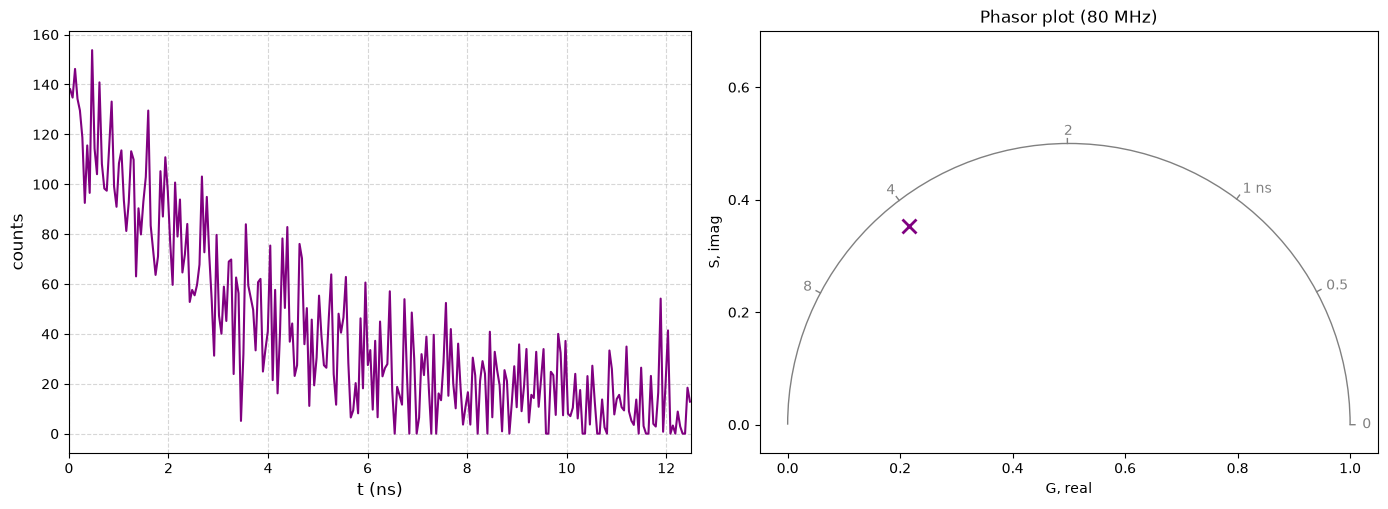

In [5]:
noise_flag = True     # toggle to add noise, higher snr = less noise
snr_db = 10

if noise_flag:
    n_noisy = add_noise(n, snr_db = snr_db)
else:
    n_noisy = n


# phasors = [phasor_calc(n, harm_n) for harm_n in range(1, 4)]  # calculate phasors for the first three harmonics
# data_and_phasor_plot(xe, n, phasors[0][0], phasors[0][1], T_laser=12.5)  # [0][1] = first harmonic, S

phasors = phasor_calc(n_noisy)  # commented the version that displays multiple harmonics

phplt.data_and_phasor_plot(time_bins, n_noisy, phasors[0], phasors[1], T_laser, exp1data)


<h3> Double exponential

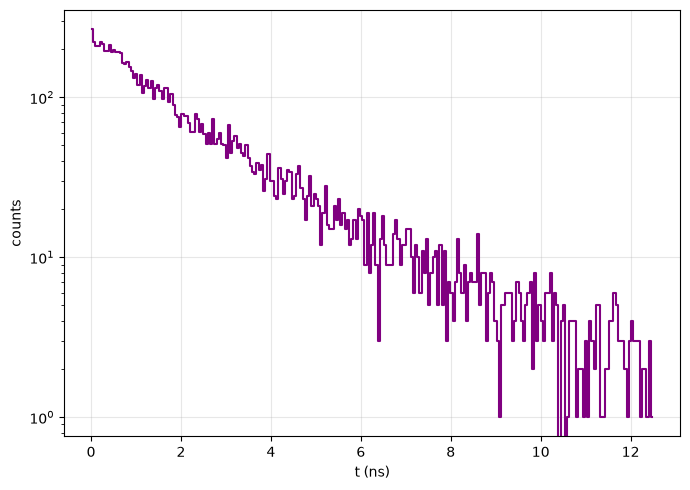

In [6]:
# Usual stuff, now for 2 curves

τ_true1, τ_true2 = 1.5, 4.0
f1 = 0.6    # ratio of intensity for the 2 curves

N_evt1 = int(N_evt * f1)   # ratio of events for the 2 curves 
N_evt2 = N_evt - N_evt1

exp2data1 = np.random.exponential(scale = τ_true1, size = N_evt1)
exp2data2 = np.random.exponential(scale = τ_true2, size = N_evt2)

time_bins = np.linspace(0, T_laser, 256)
t = 0.5 * (time_bins[:-1] + time_bins[1:])

n1, _ = np.histogram(exp2data1 % T_laser, bins = time_bins)
n2, _ = np.histogram(exp2data2 % T_laser, bins = time_bins)
n_mix = n1 + n2  


phplt.plot_decay(time_bins, n_mix)

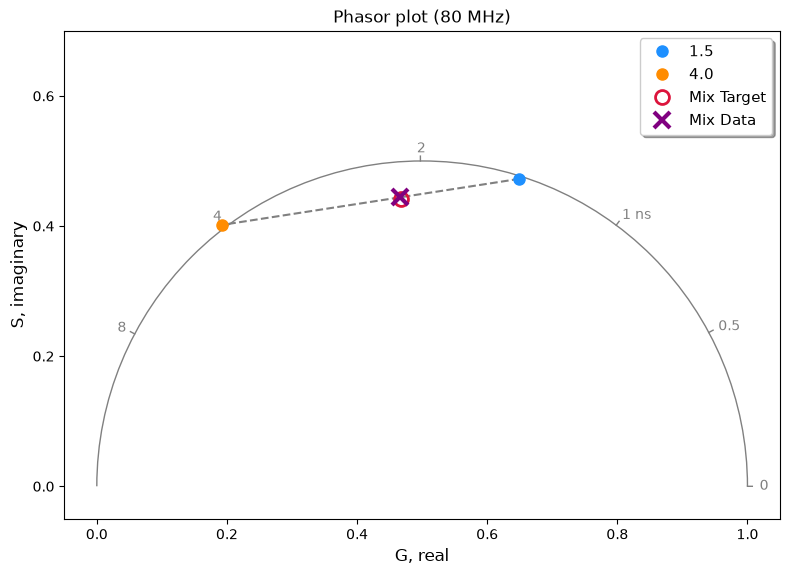

In [7]:
(G1, S1), (G2, S2), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n_mix))              # G1, G2 = phasor_calc(n1), etc
(G1_true, S1_true), (G2_true, S2_true) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))    # Here n values are taken from pure exponential in t

G_true, S_true = phasor_calc_mix([G1_true, G2_true], [S1_true, S2_true], [f1, 1 - f1])

points_mix = [
    {'G': G1, 'S': S1, 'label': f'{τ_true1}', 'color': 'dodgerblue'},
    {'G': G2, 'S': S2, 'label': f'{τ_true2}', 'color': 'darkorange'},
    {'G': G_true, 'S': S_true, 'label': 'Mix Target', 'marker': 'o', 'markerfacecolor': 'none', 'markeredgecolor': 'crimson', 'markeredgewidth': 2, 'markersize': 10, 'zorder': 2},
    {'G': G_mix, 'S': S_mix, 'label': 'Mix Data', 'color': 'purple', 'marker': 'x', 'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
]
lines_mix = [
    {'G': [G1, G2], 'S': [S1, S2], 'color': 'gray', 'ls': '--', 'lw': 1.5}
]

phplt.universal_phasor_plot(T_laser, points = points_mix, lines = lines_mix)


<h3> double exponential - segments length ratio

In [8]:
line_start = (G1, S1)   # first phasor
line_end = (G2, S2)     # second phasor

target_seg1, target_seg2 = projection_length(
    point = (G_true, S_true),
    A = line_start,
    B = line_end
)

data_seg1, data_seg2 = projection_length(
    point = (G_mix, S_mix),
    A = line_start,
    B = line_end
)

print("Mix Target:")
print(f"  f1: {target_seg1:.6f}")
print(f"  f2: {target_seg2:.6f}")
print(target_seg1/target_seg2)

print("\nMix Data:")
print(f"  f1: {data_seg1:.6f}")
print(f"  f2: {data_seg2:.6f}")
print(data_seg1/data_seg2)

Mix Target:
  f1: 0.184752
  f2: 0.278226
0.6640363393466306

Mix Data:
  f1: 0.185191
  f2: 0.277787
0.6666666666666664


<h3> double/triple exponential

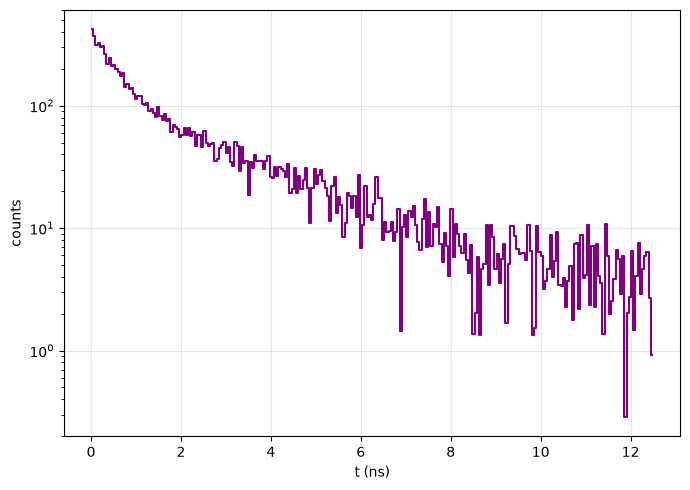

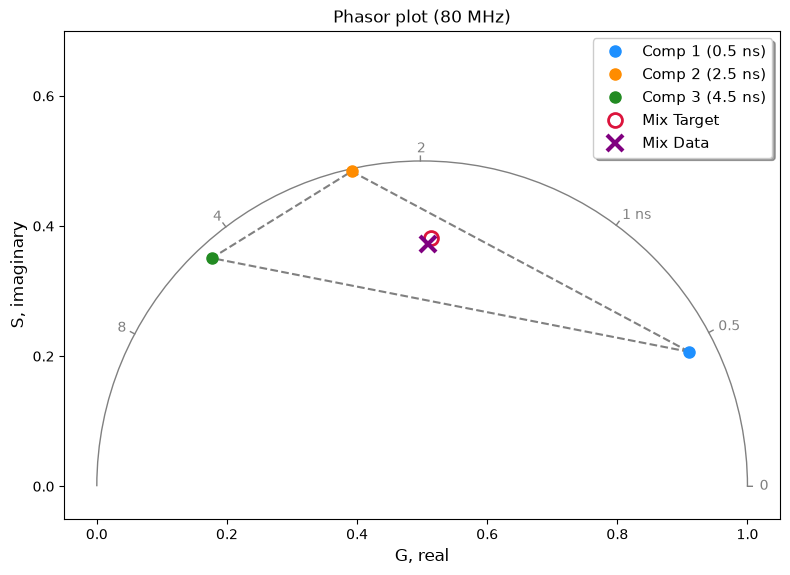

In [9]:
n_comp = 3         # SWITCH BETWEEN 2 AND 3 COMPONENTS (3 suggested for testing)
noise_flag = True
snr_db = 30

if n_comp == 2:

    τ_true1, τ_true2 = 1.5, 4.0
    f1 = 0.6
    f2 = 1.0 - f1

    N_evt1 = int(N_evt * f1)
    N_evt2 = N_evt - N_evt1

    expdata1 = np.random.exponential(scale = τ_true1, size = N_evt1)
    expdata2 = np.random.exponential(scale = τ_true2, size = N_evt2)

    n1_clean, _ = np.histogram(expdata1 % T_laser, bins = time_bins)
    n2_clean, _ = np.histogram(expdata2 % T_laser, bins = time_bins)

    if noise_flag:
        n1 = add_noise(n1_clean, snr_db = snr_db)
        n2 = add_noise(n2_clean, snr_db = snr_db)
    else:
        n1 = n1_clean.copy()
        n2 = n2_clean.copy()

    n_mix = n1 + n2

    t = 0.5 * (time_bins[:-1] + time_bins[1:])

    (G1, S1), (G2, S2), (G_mix, S_mix) = map(phasor_calc, (n1, n2, n_mix))      # phasors of data values

    (G1_true, S1_true), (G2_true, S2_true) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))     # phasors of theoric values

    G_true, S_true = phasor_calc_mix([G1_true, G2_true], [S1_true, S2_true], [f1, f2])      # final phasor of theoric value


    # DATAFRAME CREATION

    points_mix = [
        {'G': G1, 'S': S1, 'label': f'Comp 1 ({τ_true1} ns)', 'color': 'dodgerblue'},
        {'G': G2, 'S': S2, 'label': f'Comp 2 ({τ_true2} ns)', 'color': 'darkorange'},
        {'G': G_true, 'S': S_true, 'label': 'Mix Target',
         'marker': 'o', 'markerfacecolor': 'none',
         'markeredgecolor': 'crimson', 'markeredgewidth': 2,
         'markersize': 10, 'zorder': 2},
        {'G': G_mix, 'S': S_mix, 'label': 'Mix Data',
         'color': 'purple', 'marker': 'x',
         'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
    ]

    lines_mix = [
        {'G': [G1, G2], 'S': [S1, S2],
         'color': 'gray', 'ls': '--', 'lw': 1.5}
    ]

elif n_comp == 3:

    τ_true1, τ_true2, τ_true3 = 0.5, 2.5, 4.5
    f1, f2 = 0.3, 0.5
    f3 = 1.0 - f1 - f2

    N_evt1 = int(N_evt * f1)
    N_evt2 = int(N_evt * f2)
    N_evt3 = N_evt - N_evt1 - N_evt2

    expdata1 = np.random.exponential(scale = τ_true1, size = N_evt1)
    expdata2 = np.random.exponential(scale = τ_true2, size = N_evt2)
    expdata3 = np.random.exponential(scale = τ_true3, size = N_evt3)

    n1_clean, _ = np.histogram(expdata1 % T_laser, bins = time_bins)
    n2_clean, _ = np.histogram(expdata2 % T_laser, bins = time_bins)
    n3_clean, _ = np.histogram(expdata3 % T_laser, bins = time_bins)


    # ADDING NOISE

    if noise_flag:              
        n1 = add_noise(n1_clean, snr_db = snr_db)
        n2 = add_noise(n2_clean, snr_db = snr_db)
        n3 = add_noise(n3_clean, snr_db = snr_db)
    else:
        n1 = n1_clean.copy()
        n2 = n2_clean.copy()
        n3 = n3_clean.copy()

    n_mix = n1 + n2 + n3

    t = 0.5 * (time_bins[:-1] + time_bins[1:])

    (G1, S1), (G2, S2), (G3, S3), (G_mix, S_mix) = map(
        phasor_calc,
        (n1, n2, n3, n_mix)
    )

    (G1_true, S1_true), (G2_true, S2_true), (G3_true, S3_true) = map(
        phasor_calc,
        (
            np.exp(-t / τ_true1),
            np.exp(-t / τ_true2),
            np.exp(-t / τ_true3)
        )
    )

    G_true, S_true = phasor_calc_mix(
        [G1_true, G2_true, G3_true],
        [S1_true, S2_true, S3_true],
        [f1, f2, f3]
    )

    points_mix = [
        {'G': G1, 'S': S1, 'label': f'Comp 1 ({τ_true1} ns)', 'color': 'dodgerblue'},
        {'G': G2, 'S': S2, 'label': f'Comp 2 ({τ_true2} ns)', 'color': 'darkorange'},
        {'G': G3, 'S': S3, 'label': f'Comp 3 ({τ_true3} ns)', 'color': 'forestgreen'},
        {'G': G_true, 'S': S_true, 'label': 'Mix Target',
         'marker': 'o', 'markerfacecolor': 'none',
         'markeredgecolor': 'crimson', 'markeredgewidth': 2,
         'markersize': 10, 'zorder': 2},
        {'G': G_mix, 'S': S_mix, 'label': 'Mix Data',
         'color': 'purple', 'marker': 'x',
         'markersize': 12, 'markeredgewidth': 3, 'zorder': 3}
    ]

    lines_mix = [
        {'G': [G1, G2, G3, G1],
         'S': [S1, S2, S3, S1],
         'color': 'gray', 'ls': '--', 'lw': 1.5}
    ]

phplt.plot_decay(time_bins, n_mix)
phplt.universal_phasor_plot(T_laser, points=points_mix, lines=lines_mix)

Osservazione: intensità più piccola = errore più grande (ma va?), perché il rumore è generato sempre con la stessa ampiezza e quindi diventa più importante per dati "piccoli"


<h3> double/triple exponential - area ratios

In [10]:
# Only works for triple exponential!

target_areas = projection_area(
    point = (G_true, S_true),
    A = (G1_true, S1_true),
    B = (G2_true, S2_true),
    C = (G3_true, S3_true),
)

data_areas = projection_area(
    point = (G_mix, S_mix),
    A = (G1, S1),
    B = (G2, S2),
    C = (G3, S3),
)

# print(data_areas)
# print(target_areas)

print("Mix Target:")
for i, area in enumerate(target_areas, 1):
    print(f"  f{i}: {area}")

print("\nMix Data:")
for i, area in enumerate(data_areas, 1):
    print(f"  f{i}: {area}")

Mix Target:
  f1: 0.30000000000000004
  f2: 0.4999999999999998
  f3: 0.20000000000000034

Mix Data:
  f1: 0.3067418471305796
  f2: 0.4958144532198362
  f3: 0.19744369964958453


# 3. Simulation of data + IRF convolution

2 parole su cosa devo fare per vedere se ho capito. Spegazione presa dal file mmc5.pdf

IRF = Instrument Response Function, è la funzione di risposta al laser data dal rivelatore. È fondamentalmente il profilo temporale della risposta del sistema di rilevamento a un impulso laser brevissimo.

Il sistema di rilevamento infatti presenta sempre un errore nella risposta intrinseco dovuto a motivi fisici/elettronici (e quindi non riproducibile).
Studiare l'IRF permette di ottenere informazioni su questo errore e dunque correggere anche i dati raccolti.

Nel piano temporale: decadimento rilevato = convoluzione(decadimento reale, IRF)
Nel piano dei fasori: z_tot = z_exp * z_IRF




<h3> Functions for this section

In [11]:
def irf_generation(σ, μ, counts, T_laser, num_bins = 30):       # gaussian IRF

    time_bins = np.linspace(0, T_laser, num_bins)
    
    irf = np.exp(-((time_bins - μ)**2) / (2 * σ**2))
    
    irf /= np.sum(irf)
    irf *= counts
    
    return time_bins, irf



#############################################################################################################



def simulation_with_IRF(exp1data1, irf, counts, noise_flag, snr_db): 

    n_bins = len(irf)
    
    # Use a circular convolution so the signal stays consistent with the laser period.
    convol = np.fft.irfft(np.fft.rfft(exp1data1) * np.fft.rfft(irf)).real      # Here I'm using the phasor method instead of 
                                                                            # np.convolve (slow + doesn't handle periodicity)

    convol = np.clip(convol, 0, None)
    convol = (convol / np.sum(convol)) * counts  # Normalization
    
    #NOISEEEEE
    if noise_flag: noisy_signal = add_noise(convol, snr_db) 
    else: noisy_signal = convol
    
    return convol, noisy_signal




##############################################################################################################




def phasor_deconv(G_meas, S_meas, G_irf, S_irf): 
 
    z_meas = G_meas + 1j * S_meas       # imaginary unit i = 1j
    z_irf = G_irf + 1j * S_irf
    
    z_deconvol = z_meas / z_irf       # in phasor plane, convolution = multiplication
    
    G_deconvol, S_deconvol = np.real(z_deconvol), np.imag(z_deconvol)
    
    return G_deconvol, S_deconvol


In [12]:
def phase_align_phasor(G, S, reference_G, reference_S):
    '''Rotate a phasor and a reference to use the reference phase as the origin.'''

    z = G + 1j * S
    z_reference = reference_G + 1j * reference_S
    if np.isclose(np.abs(z_reference), 0):
        raise ValueError("Cannot align phasor phase: the reference phasor is zero.")

    z_aligned = z * np.exp(-1j * np.angle(z_reference))
    return np.real(z_aligned), np.imag(z_aligned)


<h3> Simulation of binned data (single exponential) + gaussian IRF 

In [13]:
# Testing the functions

T_laser = 12.5
N_evt1 = 10000
τ_true1 = 4       

μ, σ = 0.3, 0.1

exp1data1 = np.random.exponential(scale = τ_true, size = N_evt) % T_laser
time_bins = np.linspace(0, T_laser, 4096 + 1)
n1, xe1 = np.histogram(exp1data1, bins = time_bins)   

noise_bool1, snr_db1 = True, 20  

time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal, noisy_signal = simulation_with_IRF(n1, irf, N_evt1, noise_bool1, snr_db1)


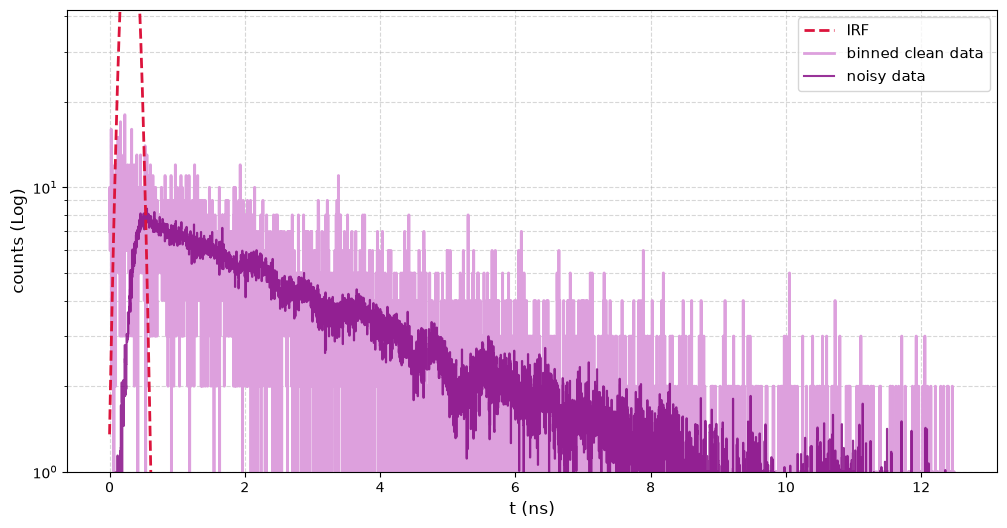

In [14]:
plt.figure(figsize = (12, 6))

signal_max = np.max(noisy_signal)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(xe1[:-1], n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal, where = 'mid', label = 'noisy data', color = 'purple', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)

plt.show()


# lascio commentata la versione plot invece di step. Non so cosa sia meglio, forse direi
# plot se uso 256 bin, step (hist) se uso 4096


# plt.figure(figsize=(12, 6))

# signal_max = np.max(noisy_signal)

# bin_centers = 0.5 * (xe1[:-1] + xe1[1:])

# plt.plot(
#     time_bins,
#     irf,
#     label="IRF",
#     color="crimson",
#     linestyle="--",
#     linewidth=2,
#     zorder=3,
# )

# plt.plot(
#     bin_centers,
#     n1,
#     label="binned clean data",
#     color="plum",
#     linewidth=2,
#     marker=None,
# )

# plt.plot(
#     time_bins,
#     noisy_signal,
#     label="noisy data",
#     color="purple",
#     alpha=0.8,
#     linewidth=1.5,
#     marker=None,
# )

# plt.yscale("log")
# plt.ylim(bottom=1, top=signal_max * 5)

# plt.xlabel("t (ns)", fontsize=12)
# plt.ylabel("counts (Log)", fontsize=12)
# plt.grid(True, which="both", linestyle="--", alpha=0.5)
# plt.legend(loc="upper right", fontsize=11)

# plt.show()

<h3> Deconvolution of signal (single exponential)

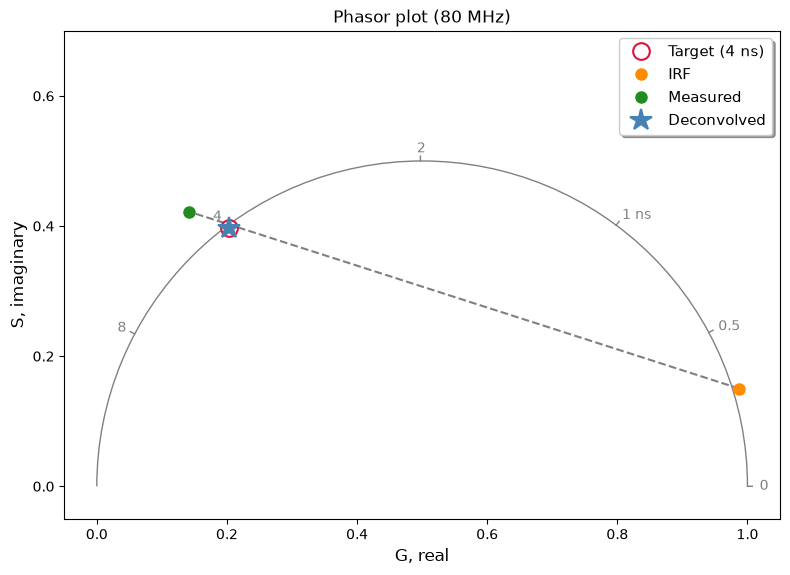

In [15]:
G_meas, S_meas = phasor_calc(noisy_signal, harm_n = 1)      # tot signal phasor
G_irf, S_irf = phasor_calc(irf, harm_n = 1)     # irf phasor

G_deconvol, S_deconvol = phasor_deconv(G_meas, S_meas, G_irf, S_irf)     # cleaned phasor (deconv of signal and irf)

n_true = np.exp(-t / τ_true)
G_true, S_true = phasor_calc(n_true)

points_mix1 = [
    {
        'G': G_true, 
        'S': S_true, 
        'label': f'Target ({τ_true} ns)', 
        'color': 'crimson', 
        'marker': 'o', 
        'markersize': 12, 
        'markeredgewidth': 1.5, 
        'markerfacecolor': 'white'
    },
    {
        'G': G_irf, 
        'S': S_irf, 
        'label': 'IRF', 
        'color': 'darkorange', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_meas, 
        'S': S_meas, 
        'label': 'Measured', 
        'color': 'forestgreen', 
        'marker': 'o', 
        'markersize': 8, 
    },
    {
        'G': G_deconvol, 
        'S': S_deconvol, 
        'label': 'Deconvolved', 
        'color': 'steelblue', 
        'marker': '*', 
        'markersize': 16, 
        'markeredgewidth': 1.5
    }
]

lines_mix1 = [
    {'G': [G_irf, G_meas], 'S': [S_irf, S_meas], 'color': 'gray', 'ls': '--', 'lw': 1.5}
]

phplt.universal_phasor_plot(T_laser, points = points_mix1, lines = lines_mix1)

<h3> Simulation of binned data (double exponential) + gaussian IRF 

Here I will be recycling some variables from previous cells. They are commented here so they can be re-defined if necessary

In [16]:
# --- FROM 2-EXP SIMULATION

τ_true1, τ_true2 = 4.0, 2

f1 = 0.7    # ratio of intensity for the 2 curves

N_evt1 = int(N_evt * f1)   # ratio of events for the 2 curves 
N_evt2 = N_evt - N_evt1

exp2data1 = np.random.exponential(scale = τ_true1, size = N_evt1)
exp2data2 = np.random.exponential(scale = τ_true2, size = N_evt2)

time_bins = np.linspace(0, T_laser, 4096 + 1)
t = 0.5 * (time_bins[:-1] + time_bins[1:])

n1, _ = np.histogram(exp2data1 % T_laser, bins = time_bins)
n2, _ = np.histogram(exp2data2 % T_laser, bins = time_bins)
n_mix = n1 + n2  


# --- FROM EXP + IRF CONVOLUTION

μ, σ = 0.25, 0.1
noise_bool1, snr_db1 = True, 20  
time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal1, noisy_signal1 = simulation_with_IRF(n_mix, irf, N_evt1, noise_bool1, snr_db1)

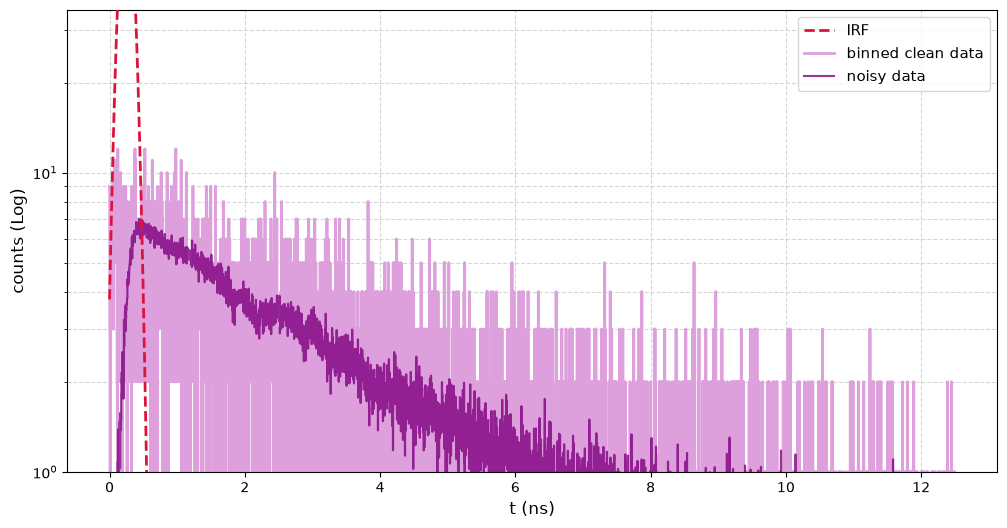

In [17]:
plt.figure(figsize = (12, 6))

signal_max = np.max(noisy_signal1)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(time_bins, n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal1, where = 'mid', label = 'noisy data', color = 'purple', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)

plt.show()

<h3> Deconvolution of signal (double exponential)


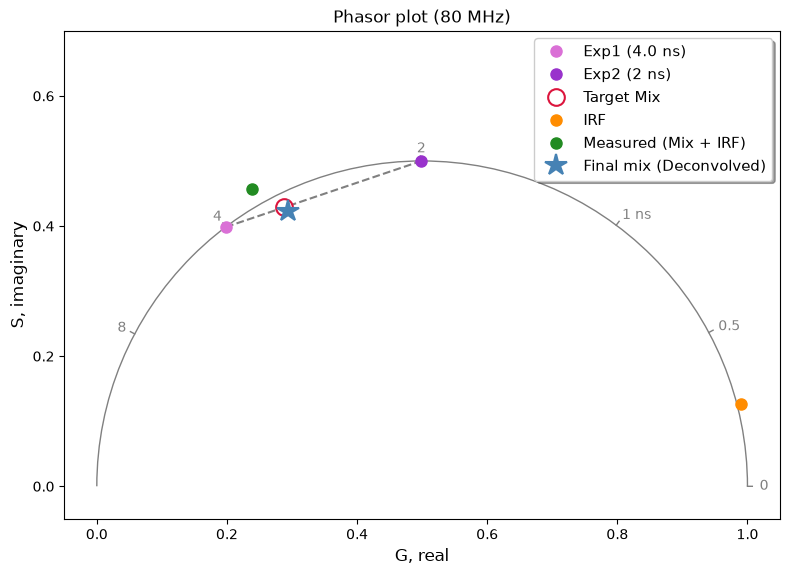

In [18]:
G_irf, S_irf = phasor_calc(irf)
G_meas, S_meas = phasor_calc(noisy_signal1)
G_deconvol, S_deconvol = phasor_deconv(G_meas, S_meas, G_irf, S_irf)

(G1t, S1t), (G2t, S2t) = map(phasor_calc, (np.exp(-t / τ_true1), np.exp(-t / τ_true2)))

G_target, S_target = phasor_calc_mix([G1t, G2t], [S1t, S2t], [f1, 1 - f1])

points_mix2 = [
    {
        'G': G1t, 
        'S': S1t, 
        'label': f'Exp1 ({τ_true1} ns)', 
        'color': 'orchid', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G2t, 
        'S': S2t, 
        'label': f'Exp2 ({τ_true2} ns)', 
        'color': 'darkorchid', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_target, 
        'S': S_target, 
        'label': 'Target Mix', 
        'color': 'crimson', 
        'marker': 'o', 
        'markersize': 12, 
        'markeredgewidth': 1.5, 
        'markerfacecolor': 'white'
    },
    {
        'G': G_irf, 
        'S': S_irf, 
        'label': 'IRF', 
        'color': 'darkorange', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_meas, 
        'S': S_meas, 
        'label': 'Measured (Mix + IRF)', 
        'color': 'forestgreen', 
        'marker': 'o', 
        'markersize': 8
    },
    {
        'G': G_deconvol, 
        'S': S_deconvol, 
        'label': 'Final mix (Deconvolved)', 
        'color': 'steelblue', 
        'marker': '*', 
        'markersize': 16, 
        'markeredgewidth': 1.5
    }
]

lines_mix2 = [
    {'G': [G1t, G2t], 'S': [S1t, S2t], 'color': 'gray', 'ls': '--', 'lw': 1.5},
#    {'G': [G_irf, G_meas], 'S': [S_irf, S_meas], 'color': 'gray', 'ls': ':', 'lw': 1.5}   # non ha senso questa
]

phplt.universal_phasor_plot(T_laser, points = points_mix2, lines = lines_mix2)

In [19]:
# Segmento teorico tra i due componenti
line_start = (G1t, S1t)
line_end = (G2t, S2t)

# Punto teorico e punto effettivo deconvoluto
target_segA, target_segB = projection_length(
    point = (G_target, S_target),
    A = line_start,
    B = line_end
)

effective_segA, effective_segB = projection_length(
    point = (G_deconvol, S_deconvol),
    A = line_start,
    B = line_end
)

f1_theory = target_segB / (target_segA + target_segB)
f2_theory = target_segA / (target_segA + target_segB)

f1_effective = effective_segB / (effective_segA + effective_segB)
f2_effective = effective_segA / (effective_segA + effective_segB)

print("Target ratios:")
print(f"  f1 = {f1_theory:.6f}")
print(f"  f2 = {f2_theory:.6f}")

print("\nMix ratios:")
print(f"  f1 = {f1_effective:.6f}")
print(f"  f2 = {f2_effective:.6f}")



Target ratios:
  f1 = 0.700000
  f2 = 0.300000

Mix ratios:
  f1 = 0.687643
  f2 = 0.312357


In [20]:
# to be added: this is interesting

# z_target = G_tm + 1j*S_tm
# z_meas = G_meas + 1j*S_meas
# z_irf = G_irf + 1j*S_irf
# z_dec = z_meas / z_irf

# print("errore deconvoluzione:",
#       abs(z_dec - z_target))

# print("errore riconvoluzione:",
#       abs(z_dec * z_irf - z_meas))

# 4. Working on an imported image - incomplete

<h3> Functions for this section

In [21]:
def extract_irf(calib_image, τ_fluor, T_laser): 

    ''' Given a calibration image with a known fluorescence lifetime, extracts the IRF phasor coordinates '''  

    tot_calib = calib_image.sum(dim = ("x", "y"))
    G_ref, S_ref = phasor_calc(tot_calib) 

    ω = 2 * np.pi / T_laser
    ωτ = ω * τ_fluor
    
    G_true = 1 / (1 + ωτ**2)
    S_true = ωτ / (1 + ωτ**2)
    G_irf, S_irf = phasor_deconv(G_ref, S_ref, G_true, S_true)
    
    return G_irf, S_irf



##############################################################################################################




def image_phasor_calc(image, harm = 1):

    '''Calculates the phasor coordinates for each pixel in a [t, x, y] image.'''

    fft_result = xr.DataArray(
        np.fft.rfft(image.values, axis=0),
        dims = ("time", "x", "y"),
        coords = {
            "x": image.coords["x"],
            "y": image.coords["y"],
        },
    )

    fft0 = fft_result.isel(time = 0).real            # fft0 = DC = intensity = total photons per pixel
    fft0 = fft0.where(fft0 != 0, 1e-10)                 # crash fix - "fills" 0 values (empty bins) with very low count

    G_img = fft_result.isel(time = harm).real / fft0
    S_img = -fft_result.isel(time = harm).imag / fft0

    return G_img, S_img, fft0



##############################################################################################################




def filter_image_phasors(image, threshold_pct=0.05):

    ''' Mask for bg noise: higher_threshold = higher noise '''

    G_img, S_img, fft0 = image_phasor_calc(image)

    count_peak = fft0.max().item()
    threshold = count_peak * threshold_pct

    mask = fft0 > threshold
    
    # print(f"Max count: {count_peak:.0f} γ. Threshold: {threshold:.0f} γ.")  
    # print(f"Pixels over threshold: {int(mask.sum())}/{mask.size}")

    G_valid = G_img.where(mask).stack(pixel = ("x", "y")).dropna("pixel")     
    S_valid = S_img.where(mask).stack(pixel = ("x", "y")).dropna("pixel")

    return G_valid, S_valid



##############################################################################################################

# useless

# def cloud_data(df_phasors):

#     """
#     Calculates average point and standard deviation of a cloud of data
#     """

#     return df_phasors.mean(), df_phasors.std()    # dataset of G and S combined
    


<h3> Incomplete test on image 1

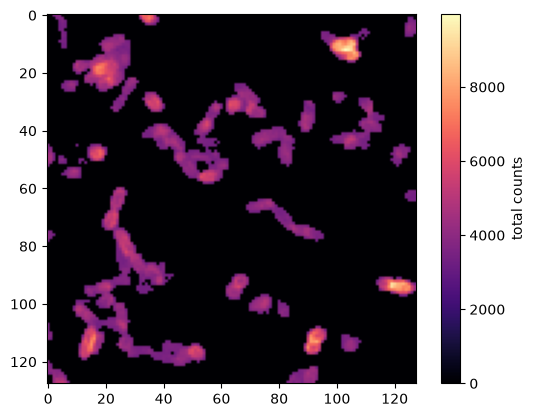

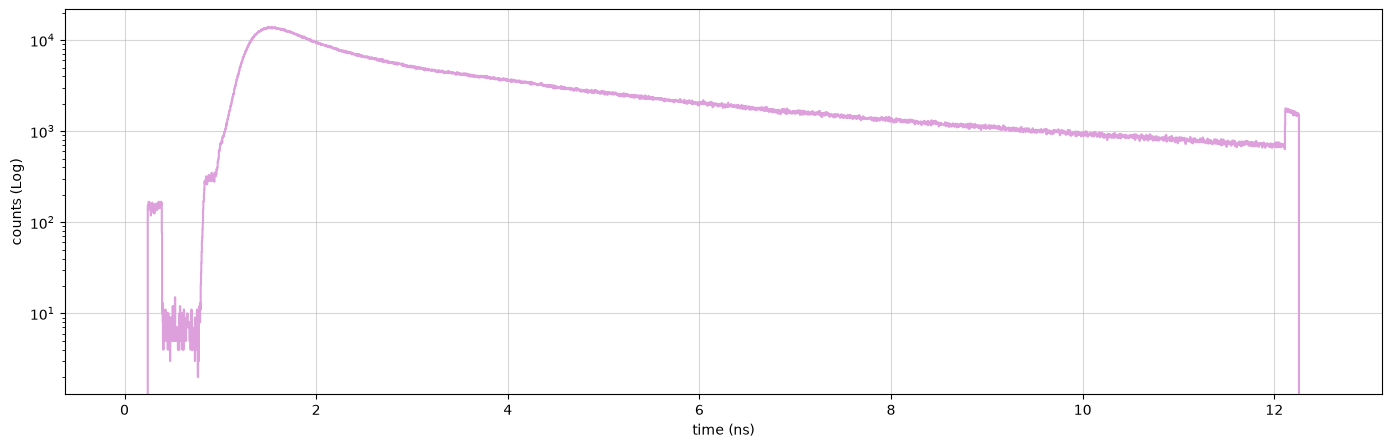

In [22]:
# plotting whole image first. Will be doing pixel selection later (see ROI selection)

image = xr.DataArray(
    tiff.imread('./data/FLIM_4_flim_Ch1.tif'),
    dims = ("time", "x", "y"),
    name = "image",
)

phplt.image_flattener(image)    # whole image
phplt.global_image_plot(image)    # whole image

<h3> Flat image, pixel and total plot

Test on image from phasor.py (embryo of zebrafish)

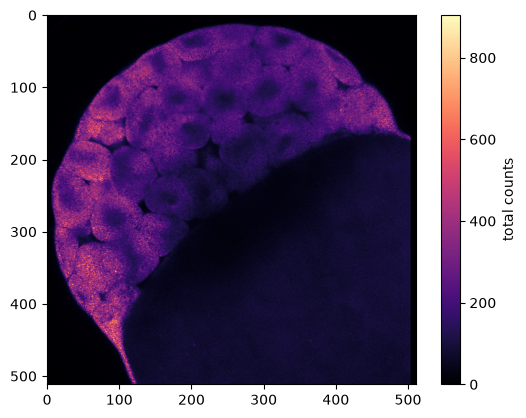

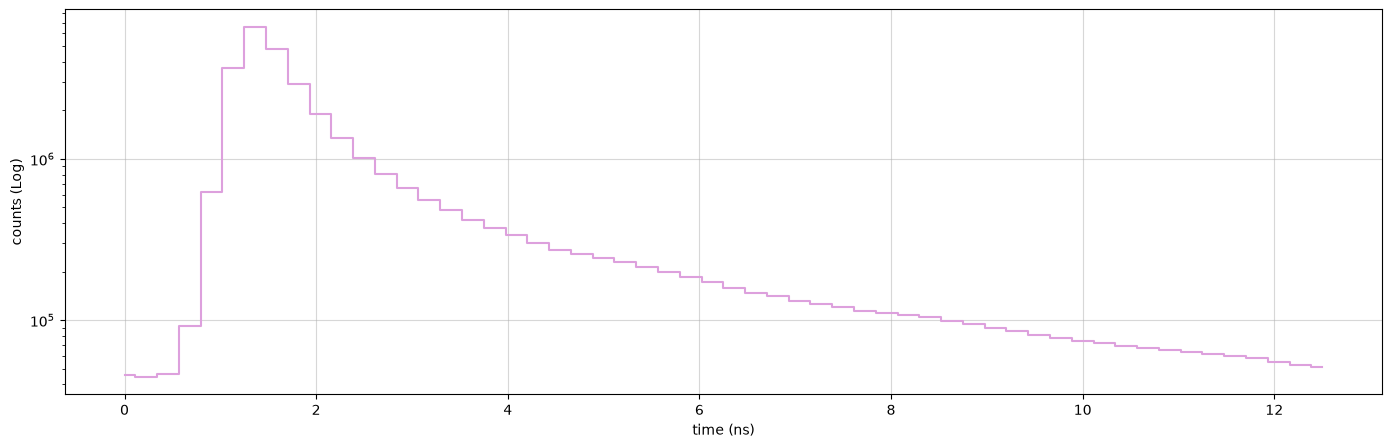

In [23]:
# https://zenodo.org/records/8046636    # I got my data from here

embryopic = xr.DataArray(
    tiff.imread(fetch('Embryo.tif')),
    dims = ("time", "x", "y"),
    name = "embryopic",
)

fluopic = xr.DataArray(
    tiff.imread(fetch('Fluorescein_Embryo.tif')),
    dims = ("time", "x", "y"),
    name = "fluopic",
)

phplt.image_flattener(embryopic)
phplt.global_image_plot(embryopic)

<h3> Calibration flat image, pixel and total plot (fluorescein was used, with a known tau of 4ns)

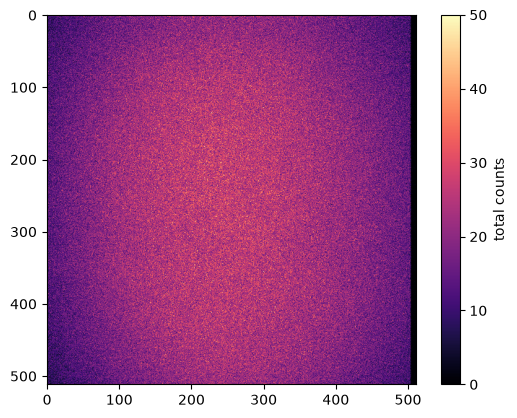

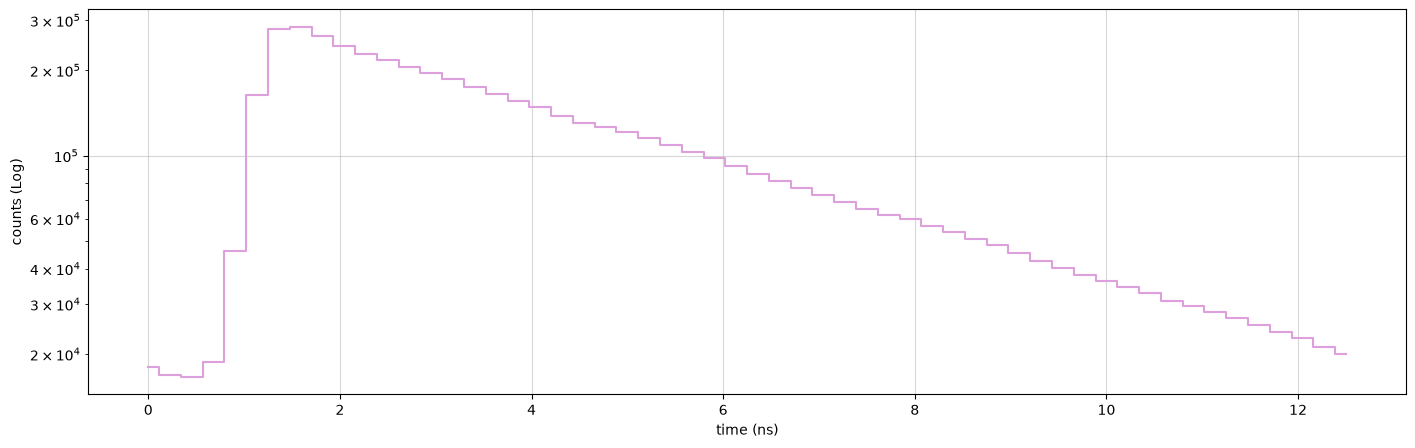

In [24]:
phplt.image_flattener(fluopic)
phplt.global_image_plot(fluopic)

<h3> IRF deconvolution

In [25]:
T_laser = 12.5
τ_fluor_true = 4.0      # LT of fluorescein (known value)    

G_irf, S_irf = extract_irf(fluopic, τ_fluor_true, T_laser)      # IRF from deconvolution
print(G_irf, S_irf)
G_irf_plot, S_irf_plot = phase_align_phasor(G_irf, S_irf, G_irf, S_irf)
G_valid, S_valid = filter_image_phasors(embryopic, threshold_pct = 0.05)
G_clean, S_clean = phasor_deconv(G_valid, S_valid, G_irf, S_irf)    # deconvolution

0.8305683585808896 0.5104261292815206


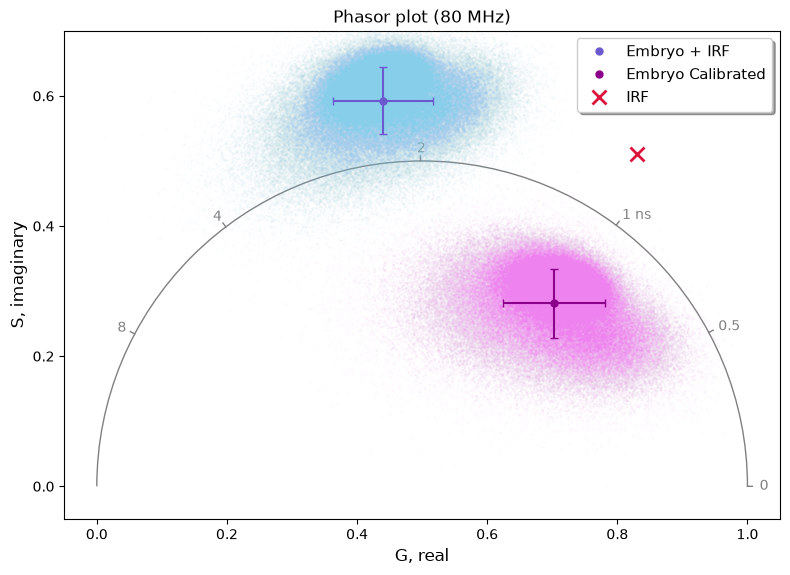

In [26]:
df_raw = pd.DataFrame({
    'G': G_valid.values,
    'S': S_valid.values
})

df_clean = pd.DataFrame({
    'G': G_clean.values,
    'S': S_clean.values
})

raw_mean = df_raw[['G', 'S']].mean()
raw_std = df_raw[['G', 'S']].std()

clean_mean = df_clean[['G', 'S']].mean()
clean_std = df_clean[['G', 'S']].std()

points_comparison = [
    {
        'G': df_raw['G'],
        'S': df_raw['S'],
        'color': 'skyblue',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.05,
        'linestyle': 'None'
    },
    {
        'G': df_clean['G'],
        'S': df_clean['S'],
        'color': 'violet',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.05,
        'linestyle': 'None'
    },
    {
        'G': raw_mean['G'],
        'S': raw_mean['S'],
        'xerr': raw_std['G'],
        'yerr': raw_std['S'],
        'label': 'Embryo + IRF',
        'color': 'slateblue',
        'marker': 'o',
        'markersize': 5,
        'zorder': 6
    },
    {
        'G': clean_mean['G'],
        'S': clean_mean['S'],
        'xerr': clean_std['G'],
        'yerr': clean_std['S'],
        'label': 'Embryo Calibrated',
        'color': 'darkmagenta',
        'marker': 'o',
        'markersize': 5,
        'zorder': 6
    },
    {
        'G': G_irf,
        'S': S_irf,
        'label': 'IRF',
        'color': 'crimson',
        'marker': 'x',
        'markersize': 10,
        'markeredgewidth': 2,
        'linestyle': 'None',
        'zorder': 7
    }
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_comparison)


# 5. Median filter and ROI selection

<h3> Median filter

Inizio facendo un riassunto teorico per verificare velocemente se ho capito bene.

Quello che mi interessa fare è un bg filter sul piano dei fasori. Ovvero:
- NON sull'immagine iniziale (rischio di eliminare strutture meno luminose perché sottili)
- NON sulla matrice G,S -> qui i punti sono vicini per posizione spaziale e non per posizione sul piano dei fasori (similitudine di tempo di decadimento). Ricadrei nello stesso errore del punto precedente

Per fare questa cosa mi viene super comodo usare phasor_filter_median() di phasorpy
https://www.phasorpy.org/docs/stable/api/filter/#phasorpy.filter.phasor_filter_median (link risorse teoriche).


In [27]:
def phasors_from_region(image, roi_mask, median_size, threshold_pct):    # ROI = region of interest

    '''Returns the median-filtered pixel-wise phasor cloud for a spatial ROI.'''

    roi_mask = np.asarray(roi_mask, dtype=bool)
    expected_shape = (image.sizes["x"], image.sizes["y"])
    if roi_mask.shape != expected_shape:
        raise ValueError(
            f"roi_mask shape {roi_mask.shape} does not match image shape {expected_shape}."
        )

    if not isinstance(median_size, int) or median_size < 1:
        raise ValueError("median_size must be a positive integer.")

    G_img, S_img, fft0 = image_phasor_calc(image)  # img

    # Filter the full image first, then select the ROI from the filtered arrays.
    fft0_med_np, G_med_np, S_med_np = phasor_filter_median(    # img -> med
        fft0.values,
        G_img.values,
        S_img.values,
        size = median_size,
        repeat = 2
    )

    # phasorpy uses NumPy internally; restore xarray immediately at the boundary.
    fft0_med = xr.DataArray(fft0_med_np, dims=fft0.dims, coords=fft0.coords)
    G_med = xr.DataArray(G_med_np, dims=G_img.dims, coords=G_img.coords)
    S_med = xr.DataArray(S_med_np, dims=S_img.dims, coords=S_img.coords)

    roi_mask_xr = xr.DataArray(
        roi_mask,
        dims=fft0.dims,
        coords=fft0.coords,
    )
    fft0_roi = fft0_med.where(roi_mask_xr)   # med -> roi
    G_roi = G_med.where(roi_mask_xr)
    S_roi = S_med.where(roi_mask_xr)

    threshold_val = fft0_roi.max(skipna=True).item() * threshold_pct
    fft0_thresh_np, G_thresh_np, S_thresh_np = phasor_threshold(
        fft0_roi.values,
        G_roi.values,
        S_roi.values,
        mean_min = threshold_val
    )
    
    fft0_thresh = xr.DataArray(fft0_thresh_np, dims=fft0.dims, coords=fft0.coords)
    G_thresh = xr.DataArray(G_thresh_np, dims=G_img.dims, coords=G_img.coords)
    S_thresh = xr.DataArray(S_thresh_np, dims=S_img.dims, coords=S_img.coords)

    valid_mask = roi_mask_xr & G_thresh.notnull() & S_thresh.notnull()
    if not valid_mask.any().item():
        raise ValueError("The ROI contains no valid pixels after filtering and thresholding.")

    return pd.DataFrame({
        "G": G_thresh.where(valid_mask, drop=True).values.ravel(),
        "S": S_thresh.where(valid_mask, drop=True).values.ravel(),
        "intensity": fft0_thresh.where(valid_mask, drop=True).values.ravel()
    })


In [28]:
# not implementing mask in this part of the code; mask is the full image size
full_mask = xr.ones_like(embryopic.isel(time = 0), dtype = bool)

# Apply the median filter inside the ROI before calculating statistics.
df_raw = phasors_from_region(embryopic, full_mask, median_size = 3, threshold_pct = 0.05)

G_clean_pixels, S_clean_pixels = phasor_deconv(df_raw["G"].to_numpy(), df_raw["S"].to_numpy(), G_irf, S_irf)

df_clean = pd.DataFrame({
    "G": G_clean_pixels,
    "S": S_clean_pixels,
    "intensity": df_raw["intensity"].to_numpy()
})

G_raw_global = df_raw["G"].mean()
S_raw_global = df_raw["S"].mean()
G_clean_global, S_clean_global = phasor_deconv(
    G_raw_global, S_raw_global, G_irf, S_irf
)

# Statistics are deliberately calculated only after filtering and deconvolution.
raw_mean = df_raw[["G", "S"]].mean()
raw_std = df_raw[["G", "S"]].std()
clean_mean = df_clean[["G", "S"]].mean()
clean_std = df_clean[["G", "S"]].std()

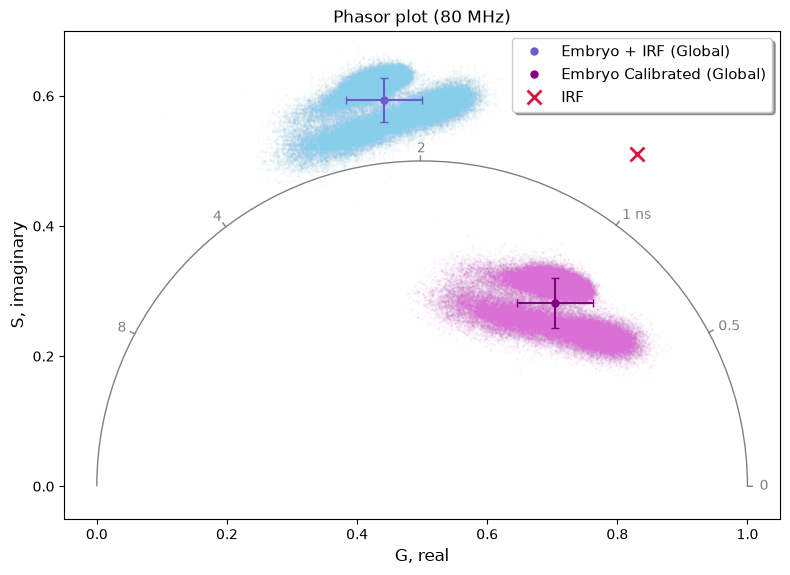

In [29]:
# PLOTTING, NOTHING TO SEE

points_comparison = [
    {
        'G': df_raw['G'],
        'S': df_raw['S'],
        'color': 'skyblue',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.05,
        'linestyle': 'None'
    },
    {
        'G': df_clean['G'],
        'S': df_clean['S'],
        'color': 'orchid',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.05,
        'linestyle': 'None'
    },
    {
        'G': G_raw_global,
        'S': S_raw_global,
        'label': 'Embryo + IRF (Global)',
        'color': 'slateblue',
        'xerr': raw_std['G'],
        'yerr': raw_std['S'],
        'marker': 'o',
        'markersize': 5,
        'zorder': 6
    },
    {
        'G': G_clean_global,
        'S': S_clean_global,
        'label': 'Embryo Calibrated (Global)',
        'color': 'purple',
        'xerr': clean_std['G'],
        'yerr': clean_std['S'],
        'marker': 'o',
        'markersize': 5,
        'zorder': 6
    },
    {
        'G': G_irf,
        'S': S_irf,
        'label': 'IRF',
        'color': 'crimson',
        'marker': 'x',
        'markersize': 10,
        'markeredgewidth': 2,
        'linestyle': 'None',
        'zorder': 7
    }
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_comparison)

<h3> ROI  selection

First of all, I plot the image using plotly, so i can choose the region of interest more easily

In [30]:
def image_flattener_plotly(image):

    ''' Plots a 2d image with the amount of photons per pixel in total time using Plotly '''
    flat_image = image.sum(dim = "time")      
    
    fig = px.imshow(
        flat_image.values, 
        color_continuous_scale = "magma",  # alternative: plasma, viridis, gray
        labels = {'color': 'total counts'},
        title = "Total Photons per Pixel"
    )
    
    fig.show()

In [31]:
image_flattener_plotly(embryopic)

In [32]:
#----ROI mask---------------------------------------------------------------------------
mask_size = 20
x_center, y_center = 81, 216

mask = xr.zeros_like(embryopic.isel(time = 0), dtype=bool)
mask.loc[{
    "x": slice(x_center - mask_size // 2, x_center + mask_size // 2 - 1),
    "y": slice(y_center - mask_size // 2, y_center + mask_size // 2 - 1),
}] = True
#---------------------------------------------------------------------------------------

# The median filter is applied first; the ROI is selected from its output.

# # Pixel-wise cloud for visualization only.
# df_raw = phasors_from_region(
#     embryopic, mask, median_size = 3, threshold_pct = 0.05
# )

# G_clean_roi, S_clean_roi = phasor_deconv(
#     df_raw["G"].to_numpy(), df_raw["S"].to_numpy(), G_irf, S_irf
# )

# df_clean = pd.DataFrame({"G": G_clean_roi, "S": S_clean_roi})
# clean_std = df_clean[["G", "S"]].std()

df_roi_filtered = phasors_from_region(
    embryopic,
    mask,
    median_size=3,
    threshold_pct=0.05
)

G_clean_roi, S_clean_roi = phasor_deconv(
    df_roi_filtered["G"].to_numpy(),
    df_roi_filtered["S"].to_numpy(),
    G_irf,
    S_irf,
)
df_roi_clean = pd.DataFrame({"G": G_clean_roi, "S": S_clean_roi})

# Statistics are calculated last, after ROI selection, median filtering and deconvolution.
roi_filtered_mean = df_roi_clean[["G", "S"]].mean()
roi_filtered_std = df_roi_clean[["G", "S"]].std()

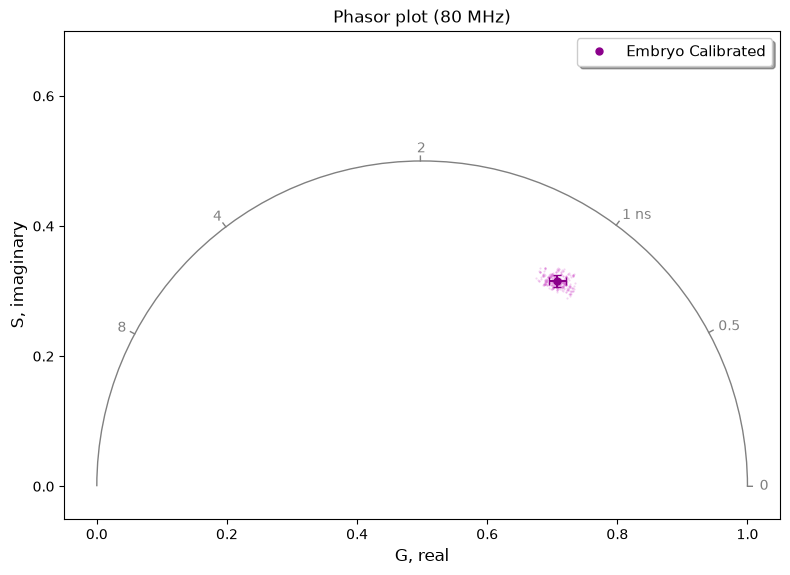

In [33]:
points_masked = [
    {
        'G': df_roi_clean['G'],
        'S': df_roi_clean['S'],
        'color': 'orchid',
        'marker': '.',
        'markersize': 1,
        'alpha': 0.3,
        'linestyle': 'None'
    },
    {
        'G': roi_filtered_mean['G'],
        'S': roi_filtered_mean['S'],
        'xerr': roi_filtered_std['G'],
        'yerr': roi_filtered_std['S'],
        'label': 'Embryo Calibrated',
        'color': 'darkmagenta',
        'marker': 'o',
        'markersize': 5,
        'zorder': 6
    },
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_masked)


Per la selezione bidirezionale immagine-piano dei fasori, preferisco aspettare di aver sistemato la parte grafica con Panel. Ho già implementato la lettura della maschera, tutto ciò che manca è tradurre selezione -> maschera

# 6. Another image

Nei file dello stesso progetto ho trovato anche uno studio con un embrione di zebrafish studiato a 5gg dalla fecondazione

In [34]:
# stolen from https://zenodo.org/records/8324901

embryopic5 = xr.DataArray(
    tiff.imread('./data/ZF-1100_noEF.tif'),
    dims = ("time", "x", "y"),
    name = "embryopic5",
)

starch_img = xr.DataArray(
    tiff.imread('./data/starch_SHG-IRF.tif'),
    dims = ("time", "x", "y"),
    name = "starch_img",
)

#__RED and GREEN filters
img_red = xr.DataArray(tiff.imread("./data/ZF-1100_607-70_filter.tif"), dims = ("time", "x", "y"))
img_green = xr.DataArray(tiff.imread("./data/ZF-1100_550-49_filter.tif"), dims = ("time", "x", "y"))

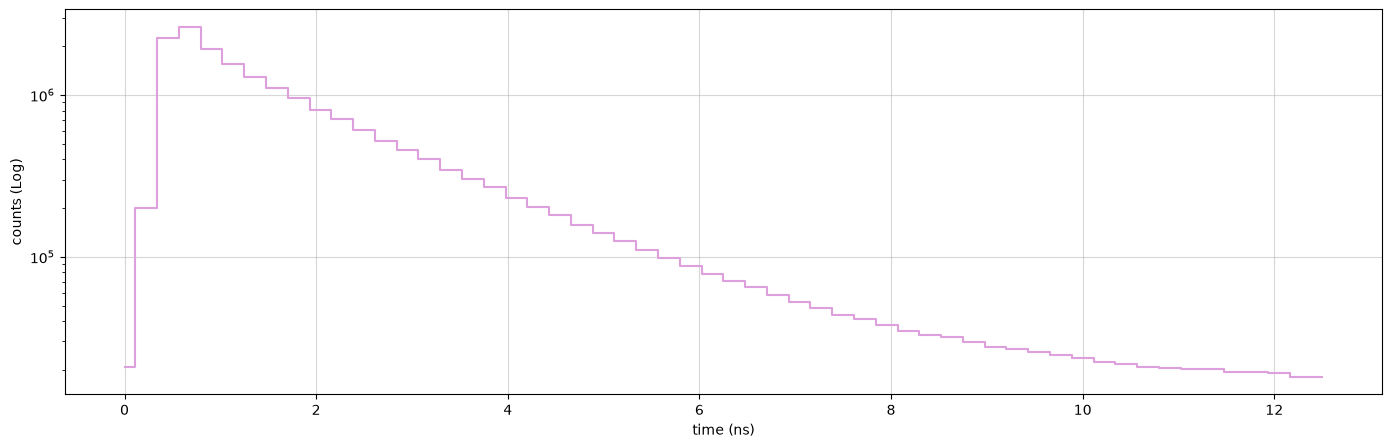

In [35]:
image_flattener_plotly(embryopic5)
phplt.global_image_plot(embryopic5)

In [36]:
image_flattener_plotly(img_red)
image_flattener_plotly(img_green)

# AYOOOO questo è interessante

In [37]:
# IRF: using calibration starch file. Starch has a tau of 0ns so it's ez
G_irf, S_irf = extract_irf(starch_img, τ_fluor = 0.0, T_laser = T_laser)

# Phasor extraction with colored filters
G_red_raw, S_red_raw = filter_image_phasors(img_red, threshold_pct = 0.05)
G_green_raw, S_green_raw = filter_image_phasors(img_green, threshold_pct = 0.05)

# IRF deconvolution from calibration file
G_red_cal, S_red_cal = phasor_deconv(G_red_raw, S_red_raw, G_irf, S_irf)
G_green_cal, S_green_cal = phasor_deconv(G_green_raw, S_green_raw, G_irf, S_irf)

# Pure decay lifetimes: A is red filter and B is green filter
A = (float(G_red_cal.mean()), float(S_red_cal.mean()))
B = (float(G_green_cal.mean()), float(S_green_cal.mean()))

print(f" Red: G = {A[0]:.3f}, S = {A[1]:.3f}")
print(f" Green: G = {B[0]:.3f}, S = {B[1]:.3f}")


 Red: G = 0.631, S = 0.457
 Green: G = 0.908, S = 0.074


applicazione filtro median su rosso, verde e totale (raw)

In [38]:
# Filtered data
df_red = phasors_from_region(img_red, roi_mask=full_mask, median_size=3, threshold_pct=0.05)
df_green = phasors_from_region(img_green, roi_mask=full_mask, median_size=3, threshold_pct=0.05)
df_emb = phasors_from_region(embryopic5, roi_mask=full_mask, median_size=3, threshold_pct=0.05)

G_red_raw, S_red_raw = df_red["G"].values, df_red["S"].values
G_green_raw, S_green_raw = df_green["G"].values, df_green["S"].values
G_emb_raw, S_emb_raw = df_emb["G"].values, df_emb["S"].values

# 3. RICALIBRAZIONE dei dati filtrati con l'IRF
G_red_cal, S_red_cal = phasor_deconv(G_red_raw, S_red_raw, G_irf, S_irf)
G_green_cal, S_green_cal = phasor_deconv(G_green_raw, S_green_raw, G_irf, S_irf)
G_emb_cal, S_emb_cal = phasor_deconv(G_emb_raw, S_emb_raw, G_irf, S_irf)

# 4. Ricalcolo dei baricentri sui dati puliti e calibrati
A = (float(np.nanmean(G_red_cal)), float(np.nanmean(S_red_cal)))
B = (float(np.nanmean(G_green_cal)), float(np.nanmean(S_green_cal)))

2 plot separati: uno con nuvola raw, nuvola deconvoluta e IRF per vedere dove si spostano i dati una volta deconvoluti; l'altro con verde rosso  e deconvoluta totale (obv anche verde e rosso sono state deconvolute nella cella prima di questa) per vedere la stellina gialla che cade sul segmento

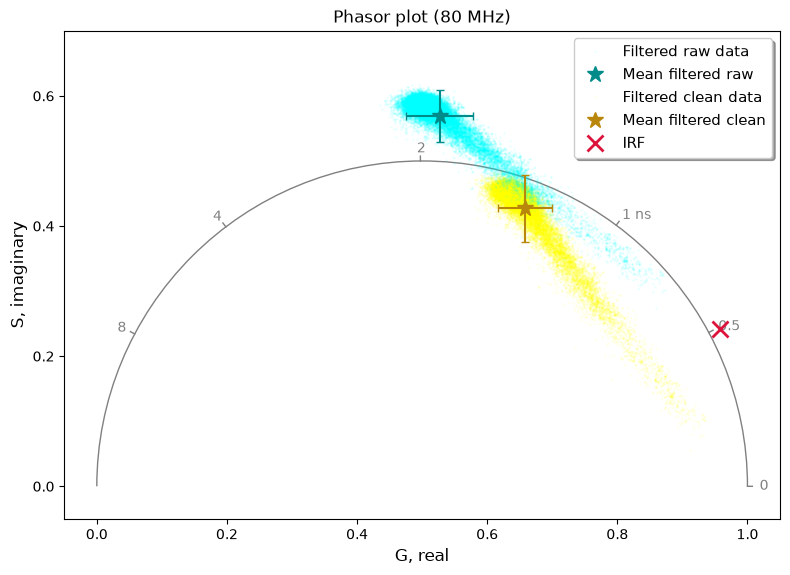

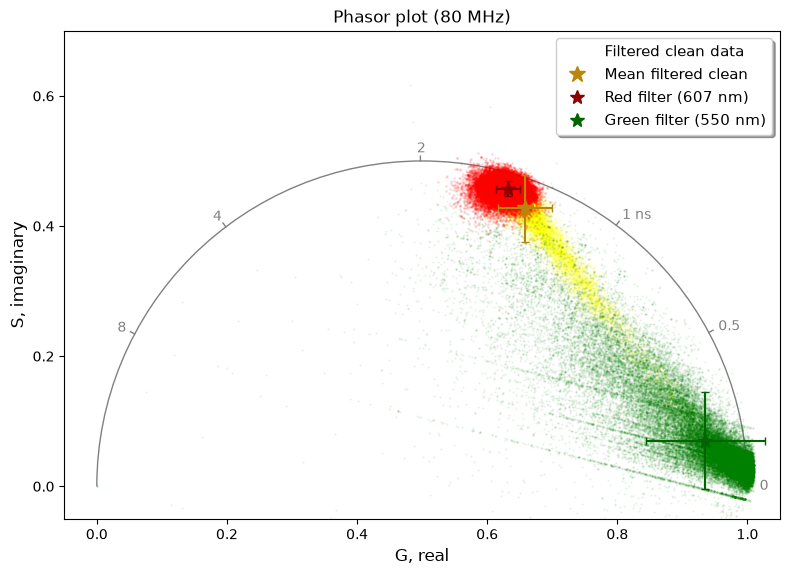

In [39]:
points_plot1 = [
    {
        'G': G_emb_raw, 'S': S_emb_raw,
        'label': 'Filtered raw data', 'color': 'cyan',
        'marker': '.', 'markersize': 2, 'alpha': 0.05, 'linestyle': 'None', 'zorder': 6
    },
    {
        'G': float(np.nanmean(G_emb_raw)), 'S': float(np.nanmean(S_emb_raw)),
        'xerr': float(np.nanstd(G_emb_raw)), 'yerr': float(np.nanstd(S_emb_raw)),
        'label': 'Mean filtered raw', 'color': 'darkcyan',
        'marker': '*', 'markersize': 12, 'linestyle': 'None', 'zorder': 9
    },
    {
        'G': G_emb_cal, 'S': S_emb_cal,
        'label': 'Filtered clean data', 'color': 'yellow',
        'marker': '.', 'markersize': 2, 'alpha': 0.05, 'linestyle': 'None', 'zorder': 5
    },
    {
        'G': float(np.nanmean(G_emb_cal)), 'S': float(np.nanmean(S_emb_cal)),
        'xerr': float(np.nanstd(G_emb_cal)), 'yerr': float(np.nanstd(S_emb_cal)),
        'label': 'Mean filtered clean', 'color': 'darkgoldenrod',
        'marker': '*', 'markersize': 12, 'linestyle': 'None', 'zorder': 9
    },
    {
        'G': G_irf, 'S': S_irf,
        'label': 'IRF', 'color': 'crimson',
        'marker': 'x', 'markersize': 12, 'markeredgewidth': 2, 'linestyle': 'None', 'zorder': 7
    }
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_plot1)


points_plot2 = [
    {
        'G': G_emb_cal, 'S': S_emb_cal,
        'label': 'Filtered clean data', 'color': 'yellow',
        'marker': '.', 'markersize': 2, 'alpha': 0.05, 'linestyle': 'None', 'zorder': 5
    },
    {
        'G': float(np.nanmean(G_emb_cal)), 'S': float(np.nanmean(S_emb_cal)),
        'xerr': float(np.nanstd(G_emb_cal)), 'yerr': float(np.nanstd(S_emb_cal)),
        'label': 'Mean filtered clean', 'color': 'darkgoldenrod',
        'marker': '*', 'markersize': 12, 'linestyle': 'None', 'zorder': 9
    },
    {
        'G': G_red_cal, 'S': S_red_cal,
        'color': 'red', 'marker': '.', 'markersize': 2, 'alpha': 0.1, 'linestyle': 'None', 'zorder': 6
    },
    {
        'G': G_green_cal, 'S': S_green_cal,
        'color': 'green', 'marker': '.', 'markersize': 1, 'alpha': 0.1, 'linestyle': 'None', 'zorder': 6
    },
    {
        'G': A[0], 'S': A[1],
        'xerr': float(np.nanstd(G_red_cal)), 'yerr': float(np.nanstd(S_red_cal)),
        'label': 'Red filter (607 nm)', 'color': 'darkred',
        'marker': '*', 'markersize': 10, 'linestyle': 'None', 'zorder': 8
    },
    {
        'G': B[0], 'S': B[1],
        'xerr': float(np.nanstd(G_green_cal)), 'yerr': float(np.nanstd(S_green_cal)),
        'label': 'Green filter (550 nm)', 'color': 'darkgreen',
        'marker': '*', 'markersize': 10, 'linestyle': 'None', 'zorder': 8
    }
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_plot2)

# bozza bozzissima ignorare

In [ ]:
# 1. Recuperiamo medie e deviazioni standard dai dati che hai plotttato
# Campione (mix)
p_samp = (float(np.nanmean(G_emb_cal)), float(np.nanmean(S_emb_cal)))
e_samp = (float(np.nanstd(G_emb_cal)), float(np.nanstd(S_emb_cal)))

# Referenze (A = Rosso, B = Verde, basandomi sul tuo points_plot2)
p_red = (A[0], A[1])
e_red = (float(np.nanstd(G_red_cal)), float(np.nanstd(S_red_cal)))

p_green = (B[0], B[1])
e_green = (float(np.nanstd(G_green_cal)), float(np.nanstd(S_green_cal)))

# 2. Monte Carlo basato su distribuzioni normali indipendenti
n_sim = 10_000
rng = np.random.default_rng()

G_samp_sim = rng.normal(p_samp[0], e_samp[0], n_sim)
S_samp_sim = rng.normal(p_samp[1], e_samp[1], n_sim)

G_red_sim = rng.normal(p_red[0], e_red[0], n_sim)
S_red_sim = rng.normal(p_red[1], e_red[1], n_sim)

G_green_sim = rng.normal(p_green[0], e_green[0], n_sim)
S_green_sim = rng.normal(p_green[1], e_green[1], n_sim)

f1_sims = np.zeros(n_sim)
f2_sims = np.zeros(n_sim)

# 3. Propagazione tramite la tua funzione custom
for i in range(n_sim):
    segA, segB = projection_length(
        point=(G_samp_sim[i], S_samp_sim[i]),
        A=(G_red_sim[i], S_red_sim[i]),
        B=(G_green_sim[i], S_green_sim[i])
    )
    # Ricalcoliamo le frazioni per ogni variante simulata
    f1_sims[i] = segB / (segA + segB)
    f2_sims[i] = segA / (segA + segB)

# 4. Estrazione dell'incertezza (deviazione standard delle frazioni calcolate)
f1_err = np.std(f1_sims)
f2_err = np.std(f2_sims)

print("\nMix ratios (con incertezze propagate):")
print(f"  f1 (Rosso) = {f1_effective:.6f} ± {f1_err:.6f}")
print(f"  f2 (Verde) = {f2_effective:.6f} ± {f2_err:.6f}")


Mix ratios (con incertezze propagate):
  f1 (Rosso) = 0.918851 ± 0.074395
  f2 (Verde) = 0.081149 ± 0.074395
